# Lab 4 — Time Series Discovery (30분)
Lab2에는 **온도 측정값이 없습니다**. 실제 door_close의 `openedAt`에서 구한 799개 열림 시간과,
기기 24대의 **교육용 합성 온도 3,456건(10분 간격, 하루)**을 분리해 적재합니다.
같은 문서를 일반/Time Series 컬렉션에 저장하고 집계 값·검사량·저장 비용을 비교합니다.
DB: `hrm_workshop_lab4`. START 포함·END 제외. 작은 샘플의 공간/시간 차이를 운영 성능으로 일반화하지 않습니다.

In [1]:
# 공통 모듈을 찾고 Lab별 독립 DB에 연결합니다. URI/비밀번호는 출력하지 않습니다.
import sys
from pathlib import Path
from datetime import datetime, timedelta, timezone
from copy import deepcopy
from collections import Counter
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lab2/events.ejson").exists())
sys.path.insert(0, str(root))
from workshop_utils import load_samples, connect, insert_once, table, ensure_search_index
events, devices = load_samples()
client, db = connect("hrm_workshop_lab4")
UTC = timezone.utc
print("기기", len(devices), "/ 이벤트", len(events), "/ 종류", dict(Counter(e["eventType"] for e in events)))
assert len(devices) == 24 and len(events) == 4959
display(table(events[:2]))

연결 성공 / MongoDB 8.0.34 / DB hrm_workshop_lab4
기기 24 / 이벤트 4959 / 종류 {'mode_snapshot': 3360, 'door_open': 800, 'door_close': 799}


,_id,deviceId,locationId,eventType,eventTime,receivedAt,schemaVersion,datasetTag,resource.href,resource.unitId,resource.component,context.modelCode,context.regionCode,context.countryCode,context.timeZone,payload.modes,notification.source,notification.capabilities
0,LAB2-D04-0-mode-0,LAB2-D04,LAB2-L04,mode_snapshot,2026-10-04 21:00:00+00:00,2026-10-04 21:00:00.300000+00:00,1,HRM_LAB2_DOOR_V1,/lab2/mode/0,0,main,LAB2-MODEL-1,DEMO-SEOUL,KR,Asia/Seoul,[MODE_01],SYNTHETIC_LAB2,[execute]
1,LAB2-D08-0-mode-0,LAB2-D08,LAB2-L08,mode_snapshot,2026-10-04 21:00:00+00:00,2026-10-04 21:00:00.300000+00:00,1,HRM_LAB2_DOOR_V1,/lab2/mode/0,0,main,LAB2-MODEL-2,DEMO-SEOUL,KR,Asia/Seoul,[MODE_01],SYNTHETIC_LAB2,[execute]


## 1. Lab2에서 닫힌 구간의 측정값 추출
미완료 OPEN은 duration에 포함하지 않습니다. 음수 시간이나 연결되지 않는 CLOSE를 확인합니다.

In [2]:
# 원본 CLOSE가 참조한 OPEN과 resource/시각이 일치하는지 검증합니다.
by_id = {e["_id"]: e for e in events}
door_measurements = []
for e in events:
    if e["eventType"] != "door_close":
        continue
    p = e["payload"]
    o = by_id[p["openEventId"]]
    assert o["deviceId"] == e["deviceId"] and o["resource"] == e["resource"]
    assert o["eventTime"] == p["openedAt"]
    duration = (e["eventTime"] - p["openedAt"]).total_seconds()
    assert duration >= 0
    door_measurements.append({"_id": e["_id"], "eventTime": e["eventTime"],
        "meta": {"deviceId": e["deviceId"], "resource": e["resource"]["href"],
                 "modelCode": e["context"]["modelCode"]},
        "durationSeconds": duration, "sourceEventId": e["_id"], "datasetTag": e["datasetTag"]})
assert len(door_measurements) == 799
display(table(door_measurements[:5]))

,_id,eventTime,durationSeconds,sourceEventId,datasetTag,meta.deviceId,meta.resource,meta.modelCode
0,LAB2-D08-0-door-0-close,2026-10-04 22:00:55+00:00,47.0,LAB2-D08-0-door-0-close,HRM_LAB2_DOOR_V1,LAB2-D08,/lab2/door/0,LAB2-MODEL-2
1,LAB2-D17-0-door-0-close,2026-10-04 22:10:53+00:00,36.0,LAB2-D17-0-door-0-close,HRM_LAB2_DOOR_V1,LAB2-D17,/lab2/door/0,LAB2-MODEL-2
2,LAB2-D03-0-door-0-close,2026-10-04 22:20:41+00:00,38.0,LAB2-D03-0-door-0-close,HRM_LAB2_DOOR_V1,LAB2-D03,/lab2/door/0,LAB2-MODEL-3
3,LAB2-D18-0-door-0-close,2026-10-04 22:21:08+00:00,50.0,LAB2-D18-0-door-0-close,HRM_LAB2_DOOR_V1,LAB2-D18,/lab2/door/0,LAB2-MODEL-3
4,LAB2-D17-0-door-1-close,2026-10-04 22:31:02+00:00,45.0,LAB2-D17-0-door-1-close,HRM_LAB2_DOOR_V1,LAB2-D17,/lab2/door/0,LAB2-MODEL-2


In [3]:
# 일정한 주기로 측정하는 센서 실습용 온도입니다. 원본에서 관측한 값이 아닙니다.
import math
temperature_measurements = []
anchor = datetime(2026, 10, 5, tzinfo=UTC)
for device_number, device in enumerate(devices):
    for sample_number in range(144):
        value = round(3.0 + 0.15 * (device_number % 3) + 0.7 * math.sin(sample_number / 12), 3)
        temperature_measurements.append({"_id": f"temp-{device['_id']}-{sample_number}",
            "eventTime": anchor + timedelta(minutes=10 * sample_number),
            "meta": {"deviceId": device["_id"], "resource": "/synthetic/temperature/fridge",
                     "modelCode": device["product"]["modelCode"]},
            "temperatureC": value, "datasetTag": "SYNTHETIC_LAB4_TEMPERATURE_V1"})
assert len(temperature_measurements) == 3456
display(table(temperature_measurements[:3]))

,_id,eventTime,temperatureC,datasetTag,meta.deviceId,meta.resource,meta.modelCode
0,temp-LAB2-D01-0,2026-10-05 00:00:00+00:00,3.000,SYNTHETIC_LAB4_TEMPERATURE_V1,LAB2-D01,/synthetic/temperature/fridge,LAB2-MODEL-1
1,temp-LAB2-D01-1,2026-10-05 00:10:00+00:00,3.058,SYNTHETIC_LAB4_TEMPERATURE_V1,LAB2-D01,/synthetic/temperature/fridge,LAB2-MODEL-1
2,temp-LAB2-D01-2,2026-10-05 00:20:00+00:00,3.116,SYNTHETIC_LAB4_TEMPERATURE_V1,LAB2-D01,/synthetic/temperature/fridge,LAB2-MODEL-1


## 2. 새 Time Series 컬렉션 생성
timeField=`eventTime`, metaField=`meta`. eventId·변하는 값은 meta에 넣지 않습니다.
10분 온도는 `minutes`, 비정기 문 이벤트는 `seconds`를 시작값으로 비교합니다.
고정 2026년 샘플이 현재 시각 기준 TTL로 사라지지 않도록 본 비교 컬렉션에는 TTL을 설정하지 않습니다.
Time Series에는 unique _id 보장이 없고 기존 일반 컬렉션을 제자리 변환할 수도 없습니다.

In [4]:
# 재실행은 적재 완료 컬렉션을 재사용합니다. 부분 적재 상태는 중복을 만들지 않고 중단합니다.
def prepare_pair(prefix, documents, granularity):
    regular = db[prefix + "_regular"]
    ts_name = prefix + "_ts"
    if ts_name not in db.list_collection_names():
        db.create_collection(ts_name, timeseries={"timeField": "eventTime", "metaField": "meta",
                                                 "granularity": granularity})
    ts = db[ts_name]
    options = ts.options()
    assert options["timeseries"]["timeField"] == "eventTime" and options["timeseries"]["metaField"] == "meta"
    insert_once(regular, documents)
    count = ts.count_documents({})
    if count == 0:
        # 같은 meta를 모아서 순차 배치 적재합니다. Time Series에서는 upsert 중복 방지를 사용하지 않습니다.
        ordered_docs = sorted(documents, key=lambda d: (d["meta"]["deviceId"], d["eventTime"]))
        for start in range(0, len(ordered_docs), 500):
            ts.insert_many(deepcopy(ordered_docs[start:start + 500]), ordered=True)
    elif count != len(documents):
        raise RuntimeError("부분 적재 상태입니다. 새 prefix로 다시 실행하세요.")
    for collection in (regular, ts):
        collection.create_index([("meta.deviceId", 1), ("eventTime", 1)], name="device_time")
        assert collection.count_documents({}) == len(documents)
    return regular, ts
door_regular, door_ts = prepare_pair("door_duration_v1", door_measurements, "seconds")
temp_regular, temp_ts = prepare_pair("temperature_v1", temperature_measurements, "minutes")
display(table(temp_ts.list_indexes()))

,v,name,key.meta,key.eventTime,key.meta.deviceId
0,2,meta_1_eventTime_1,1.0,1,NaN
1,2,device_time,NaN,1,1.0


In [5]:
# 같은 장치·같은 하루를 UTC 1시간 버킷으로 집계해 결과가 완전히 같은지 확인합니다.
START, END = anchor, anchor + timedelta(days=1)
pipeline = [
    {"$match": {"meta.deviceId": "LAB2-D01", "eventTime": {"$gte": START, "$lt": END}}},
    {"$group": {"_id": {"$dateTrunc": {"date": "$eventTime", "unit": "hour", "timezone": "UTC"}},
                "count": {"$sum": 1}, "avgC": {"$avg": "$temperatureC"},
                "minC": {"$min": "$temperatureC"}, "maxC": {"$max": "$temperatureC"}}},
    {"$sort": {"_id": 1}}
]
regular_result = list(temp_regular.aggregate(pipeline))
ts_result = list(temp_ts.aggregate(pipeline))
assert regular_result == ts_result and sum(r["count"] for r in ts_result) == 144
display(table(ts_result))
# 완료된 열림 구간도 같은 기기별 집계로 비교합니다. 미완료 구간은 제외합니다.
door_pipeline = [{"$group": {"_id": "$meta.deviceId", "count": {"$sum": 1},
                  "sumSeconds": {"$sum": "$durationSeconds"}, "avgSeconds": {"$avg": "$durationSeconds"}}},
                 {"$sort": {"_id": 1}}]
assert list(door_regular.aggregate(door_pipeline)) == list(door_ts.aggregate(door_pipeline))
print("일반/Time Series 두 데이터셋의 집계 일치 OK")

,_id,count,avgC,minC,maxC
0,2026-10-05 00:00:00+00:00,6,3.143167,3.000,3.283
1,2026-10-05 01:00:00+00:00,6,3.451000,3.336,3.556
2,2026-10-05 02:00:00+00:00,6,3.647833,3.589,3.692
3,2026-10-05 03:00:00+00:00,6,3.686500,3.659,3.700
4,2026-10-05 04:00:00+00:00,6,3.556833,3.464,3.637
5,2026-10-05 05:00:00+00:00,6,3.290833,3.156,3.419
6,2026-10-05 06:00:00+00:00,6,2.953833,2.810,3.099
7,2026-10-05 07:00:00+00:00,6,2.627833,2.510,2.754
8,2026-10-05 08:00:00+00:00,6,2.393333,2.330,2.470
9,2026-10-05 09:00:00+00:00,6,2.307167,2.300,2.316


일반/Time Series 두 데이터셋의 집계 일치 OK


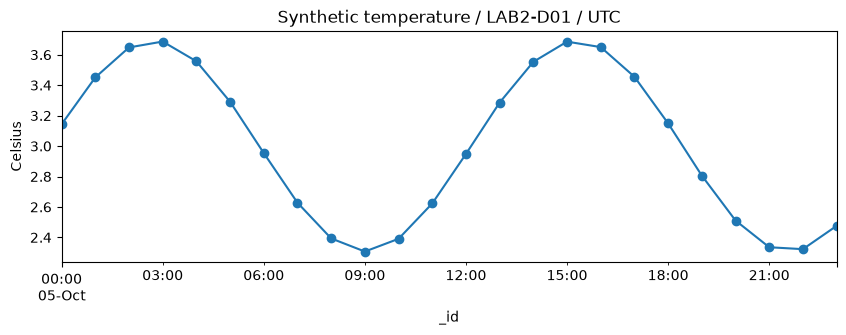

,collection,count,storageSize,indexSize
0,door_duration_v1_regular,799,53248,81920
1,door_duration_v1_ts,799,65536,94208
2,temperature_v1_regular,3456,135168,200704
3,temperature_v1_ts,3456,20480,40960


temperature_v1_regular


{'explainVersion': '2',
 'stages': [{'$cursor': {'queryPlanner': {'namespace': 'hrm_workshop_lab4.temperature_v1_regular',
     'parsedQuery': {'$and': [{'meta.deviceId': {'$eq': 'LAB2-D01'}},
       {'eventTime': {'$lt': datetime.datetime(2026, 10, 6, 0, 0)}},
       {'eventTime': {'$gte': datetime.datetime(2026, 10, 5, 0, 0)}}]},
     'indexFilterSet': False,
     'queryHash': '4B2401C1',
     'planCacheShapeHash': '4B2401C1',
     'planCacheKey': '5BEA9714',
     'optimizationTimeMillis': 0,
     'maxIndexedOrSolutionsReached': False,
     'maxIndexedAndSolutionsReached': False,
     'maxScansToExplodeReached': False,
     'prunedSimilarIndexes': False,
     'winningPlan': {'isCached': False,
      'queryPlan': {'stage': 'GROUP',
       'planNodeId': 4,
       'inputStage': {'stage': 'FETCH',
        'planNodeId': 2,
        'inputStage': {'stage': 'IXSCAN',
         'planNodeId': 1,
         'keyPattern': {'meta.deviceId': 1, 'eventTime': 1},
         'indexName': 'device_time',
  

temperature_v1_ts


{'explainVersion': '2',
 'stages': [{'$cursor': {'queryPlanner': {'namespace': 'hrm_workshop_lab4.system.buckets.temperature_v1_ts',
     'parsedQuery': {'$and': [{'meta.deviceId': {'$eq': 'LAB2-D01'}},
       {'_id': {'$lt': ObjectId('6ac43a000000000000000000')}},
       {'_id': {'$gte': ObjectId('6ac197000000000000000000')}},
       {'control.max.eventTime': {'$_internalExprGte': datetime.datetime(2026, 10, 5, 0, 0)}},
       {'control.min.eventTime': {'$_internalExprGte': datetime.datetime(2026, 10, 4, 0, 0)}},
       {'control.max.eventTime': {'$_internalExprLt': datetime.datetime(2026, 10, 7, 0, 0)}},
       {'control.min.eventTime': {'$_internalExprLt': datetime.datetime(2026, 10, 6, 0, 0)}}]},
     'indexFilterSet': False,
     'queryHash': '9C023820',
     'planCacheShapeHash': '9C023820',
     'planCacheKey': 'CB471F1C',
     'optimizationTimeMillis': 1,
     'maxIndexedOrSolutionsReached': False,
     'maxIndexedAndSolutionsReached': False,
     'maxScansToExplodeReached': Fa

In [6]:
# 시간별 온도 평균을 시각화합니다. x축은 UTC이며 실습용 합성 데이터입니다.
import matplotlib.pyplot as plt
frame = table(ts_result).set_index("_id")
frame["avgC"].plot(marker="o", figsize=(10, 3), title="Synthetic temperature / LAB2-D01 / UTC")
plt.ylabel("Celsius")
plt.show()
# 공간 사용량은 padding·인덱스·작은 데이터 효과를 포함하므로 직접 관측값으로만 비교합니다.
costs = []
for collection in (door_regular, door_ts, temp_regular, temp_ts):
    stats = db.command("collStats", collection.name)
    costs.append({"collection": collection.name, "count": collection.count_documents({}),
                  "storageSize": stats.get("storageSize"), "indexSize": stats.get("totalIndexSize")})
display(table(costs))
# explain 출력 구조는 일반/TS 실행 엔진에 따라 달라질 수 있어 전체 결과를 확인합니다.
for collection in (temp_regular, temp_ts):
    print(collection.name)
    display(db.command("explain", {"aggregate": collection.name, "pipeline": pipeline, "cursor": {}},
                       verbosity="executionStats"))

## 3. TTL 확장 실습 (선택)
TTL은 eventTime 기준이며 bucket 단위 비동기 제거입니다. 정확히 60초 후 사라진다고 가정하면 안 됩니다.
아래 플래그를 켜면 **별도 TTL 컬렉션**에 현재 시각의 합성 측정값 1건을 적재합니다.
본 집계용 컬렉션에는 영향을 주지 않습니다. 늦게 도착한 오래된 값은 즉시 만료 대상이 될 수 있습니다.

In [7]:
# TTL 관찰은 선택 실행입니다. 운영 보존 기간은 이 60초 실습 값으로 결정하지 않습니다.
RUN_TTL_DEMO = False
if RUN_TTL_DEMO:
    if "ttl_demo" not in db.list_collection_names():
        db.create_collection("ttl_demo", timeseries={"timeField": "eventTime", "metaField": "meta",
                             "granularity": "seconds"}, expireAfterSeconds=60)
    db.ttl_demo.insert_one({"eventTime": datetime.now(UTC), "meta": {"deviceId": "SYNTHETIC-TTL"},
                            "temperatureC": 3.0})
    print("비동기 TTL 관찰: 잠시 후 db.ttl_demo.count_documents({})를 재실행하세요.")
else:
    print("TTL 옵션 코드 준비 완료 / 본 데이터의 TTL 없음")
client.close()  # 모든 집계가 끝난 후 연결을 정리합니다.

TTL 옵션 코드 준비 완료 / 본 데이터의 TTL 없음


## 리뷰
- eventId·mode를 meta에 넣으면 bucket 효율에 어떤 영향이 있을까요?
- Time Series의 중복 방지는 일반 원본 이력/수집 checkpoint에서 설계해야 합니다.
- 최신 상태 갱신·unique 키·트랜잭션 쓰기는 일반 컬렉션과 역할을 나누세요.

[Time Series](https://www.mongodb.com/docs/manual/core/timeseries-collections/) ·
[제약](https://www.mongodb.com/docs/manual/core/timeseries/timeseries-limitations/) ·
[TTL](https://www.mongodb.com/docs/manual/core/timeseries/timeseries-automatic-removal/)

## Kafka Connect 연결 가이드 — 준비와 연결 흐름

이 섹션은 Kafka 환경에서 실습을 확장하는 **가이드**입니다. 아래 코드는 Markdown 예시이므로
Run All로 Kafka 등록·발행이 자동 실행되지 않습니다. 실제 환경의 주소·인증을 채운 후 별도 셀/터미널에서 실행하세요.
현재 저장된 실행 결과는 PyMongo 직접 적재 결과입니다.

```text
노트북 Producer ── bootstrap.servers ──▶ Kafka Broker / 토픽
                                           │
                         Kafka Connect Worker (MongoDB Sink plugin)
                                           │ connection.uri
                                           ▼
                                     MongoDB Atlas

노트북 ── Connect REST API (:8083 예시) ──▶ Connector 등록·상태 확인
```

### 1. 주소 세 가지를 구분합니다

| 주소 | 용도 | 교육용 예시 |
|---|---|---|
| Kafka bootstrap server | Producer/Consumer와 Connect worker가 Broker 접속 | `localhost:9092` |
| Connect REST URL | Connector 등록·설정 검증·상태 확인 | `http://localhost:8083` |
| MongoDB URI | Connect worker가 Atlas 접속 | `mongodb+srv://<user>:<password>@<cluster>/` |

Docker 내부 worker의 `localhost`는 worker 컨테이너 자신입니다. Broker의 advertised.listeners는
노트북과 worker 각각에서 접근 가능해야 합니다(예: 호스트 `localhost:9092`, 내부 `kafka:29092`).
Atlas Network Access에는 **Connect worker의 출구 IP**가 필요합니다. 노트북 접속 성공만으로 worker 접속이 보장되지 않습니다.
클라우드 Kafka라면 Broker/REST 각각의 TLS·SASL·인증 정보를 해당 서비스 방식으로 적용하세요.

### 2. Worker 준비

1. Kafka Broker와 Kafka Connect distributed worker를 준비합니다.
2. MongoDB Kafka Connector 배포 JAR/패키지를 **모든 worker의 plugin.path**에 설치하고 worker를 재시작합니다.
3. worker의 `bootstrap.servers`와 내부 config/offset/status 토픽을 설정합니다.
   단일 Broker 실습은 내부 토픽 replication factor를 `1`로 설정합니다. 운영 값은 Broker 구성에 맞춥니다.
4. `GET /connector-plugins`에 `com.mongodb.kafka.connect.MongoSinkConnector`가 보이는지 확인합니다.
5. MongoDB URI는 worker의 ConfigProvider로 주입합니다. OpenCode MCP 설정은 Connect에 자동 전달되지 않습니다.

worker properties 예시(실제 worker 설정 파일에 추가):

```properties
# Kafka 표준 파일 ConfigProvider를 worker에서 활성화합니다.
config.providers=file
config.providers.file.class=org.apache.kafka.common.config.provider.FileConfigProvider
```

모든 worker에서 읽을 수 있는 `/run/secrets/mongodb.properties`에 `uri=<실제 URI>`를 저장하고
접근 권한을 제한합니다. 아래 Connector JSON은 `${file:/run/secrets/mongodb.properties:uri}`를 참조합니다.
이 경로는 **worker 파일시스템 경로**입니다. 노트북의 로컬 인증 파일 경로와 다릅니다.

### 3. REST 등록 순서

아래 `sink-config.json`은 각 Lab에서 제공하는 **config 객체만** 담은 파일입니다.

```bash
# plugin 설치 상태를 확인합니다.
curl --fail-with-body http://localhost:8083/connector-plugins

# 등록 전에 Connector 설정을 검증합니다. error_count=0인지 확인합니다.
curl --fail-with-body -X PUT \
  http://localhost:8083/connector-plugins/com.mongodb.kafka.connect.MongoSinkConnector/config/validate \
  -H 'Content-Type: application/json' --data-binary @sink-config.json

# 예시 이름 hrm-lab-sink로 Connector 설정을 등록/갱신합니다.
curl --fail-with-body -X PUT http://localhost:8083/connectors/hrm-lab-sink/config \
  -H 'Content-Type: application/json' --data-binary @sink-config.json

# Connector와 모든 task가 RUNNING인지 확인합니다.
curl --fail-with-body http://localhost:8083/connectors/hrm-lab-sink/status
```

`/status`의 task가 FAILED이면 trace와 worker 로그를 확인합니다. 설정 검증 성공은 실제 Atlas 접속 성공이 아닙니다.

### 4. 메시지 계약과 오류 처리

- `lab2/events.ejson`은 **JSON 배열**입니다. 배열 전체를 한 메시지로 보내지 말고 이벤트 객체 한 건씩 발행합니다.
- 발행 재시도에도 이벤트 `_id`를 유지합니다. Kafka key는 기기+리소스 조합으로 설정하여 같은 상태 키를 같은 partition에 보냅니다.
- partition 내부 전달 순서는 eventTime 순서와 다를 수 있습니다. 같은 시각 판정·부분 payload는 생산자 버전 계약이 필요합니다.
- Connect는 재시작/offset 재처리 시 같은 레코드를 재전달할 수 있습니다. 아래 기본 예시를 end-to-end exactly-once로 해석하지 않습니다.
- 기본 예시는 `errors.tolerance=none`으로 실패를 드러냅니다. 오류를 넘기려면 DLQ와 경보를 함께 구성합니다.
  단일 Broker 예시: `errors.tolerance=all`, `errors.deadletterqueue.topic.name=hrm.dlq`,
  `errors.deadletterqueue.topic.replication.factor=1`, `errors.deadletterqueue.context.headers.enable=true`.
  적용 후 정상 건수+DLQ 건수+offset/lag를 함께 확인하고 실패 원인 수정 후 재처리합니다.

### 5. 공통 확인표

| 관측 지점 | 확인 항목 |
|---|---|
| Producer | 발행 성공 callback/flush, 실제 발행 건수 |
| Kafka | topic/partition/offset, consumer group lag |
| Connect | Connector 및 task RUNNING, worker 로그, 실패/DLQ |
| Atlas | 대상 namespace, `_id`, BSON Date 타입, 건수·집계 |

`RUNNING`만으로 완료를 판정하지 말고 특정 이벤트 ID의 Atlas 도착까지 확인합니다.

공식 가이드:
[설치](https://www.mongodb.com/docs/kafka-connector/current/introduction/install/) ·
[전체 설정](https://www.mongodb.com/docs/kafka-connector/current/sink-connector/configuration-properties/all-properties/) ·
[ID 전략](https://www.mongodb.com/docs/kafka-connector/current/sink-connector/fundamentals/post-processors/) ·
[쓰기 전략](https://www.mongodb.com/docs/kafka-connector/current/sink-connector/fundamentals/write-strategies/)

## Lab 4와 Kafka 연결 — 측정 토픽에서 Time Series로

```text
원본 이벤트 → 일반 이력 (중복 검증)
                   ↓ 측정 변환 / 수집 checkpoint
          hrm.lab4.temperature → MongoDB Sink → kafka_temperature_ts
```

Lab2 원본에는 온도가 없습니다. 이 노트북의 `temperature_measurements`는 합성 온도이며
`door_measurements`는 원본 OPEN/CLOSE에서 계산한 완료 구간입니다.
Connector는 문 열림 시간을 자동 계산하지 않습니다. Producer/업무 처리기가 먼저 측정 문서로 변환합니다.

### Time Series Sink 설정 예시

```json
{
  "connector.class": "com.mongodb.kafka.connect.MongoSinkConnector",
  "topics": "hrm.lab4.temperature",
  "connection.uri": "${file:/run/secrets/mongodb.properties:uri}",
  "database": "hrm_workshop_lab4",
  "collection": "kafka_temperature_ts",
  "tasks.max": "1",
  "key.converter": "org.apache.kafka.connect.storage.StringConverter",
  "value.converter": "org.apache.kafka.connect.json.JsonConverter",
  "value.converter.schemas.enable": "false",
  "timeseries.timefield": "eventTime",
  "timeseries.timefield.auto.convert": "true",
  "timeseries.metafield": "meta",
  "timeseries.granularity": "minutes",
  "timeseries.expire.after.seconds": "0",
  "writemodel.strategy": "com.mongodb.kafka.connect.sink.writemodel.strategy.InsertOneDefaultStrategy",
  "errors.tolerance": "none"
}
```

`eventTime`をepoch millisecondsの数値として送り、Connectorのauto.convertでBSON Dateへ変換します。
文字列を使う場合はJava DateTimeFormatter形式も合わせます。変換失敗は元の値が渡るので
Atlasが求めるDateにならず書き込み失敗する可能性があります。
TTL=0은 고정된 2026년 데이터가 사라지지 않게 하는 실습 설정입니다.
기존 컬렉션의 TTL이 자동 해제된다고 가정하지 말고 options를 확인합니다.

새 `kafka_temperature_ts`를 사용하고, 미리 생성한다면
`timeField=eventTime, metaField=meta, granularity=minutes`를 일치시킵니다.
일반 컬렉션이 같은 이름으로 존재하면 다른 이름을 사용합니다.

```python
# 앞에서 만든 합성 측정값을 한 문서씩 JSON으로 변환하여 발행합니다.
import json
from copy import deepcopy
from confluent_kafka import Producer

producer = Producer({"bootstrap.servers": "localhost:9092"})
delivery_errors = []

def delivered(error, message):
    # 발행 성공/실패를 flush 후 확인합니다.
    if error is not None:
        delivery_errors.append(str(error))

for measurement in temperature_measurements:
    wire = deepcopy(measurement)
    wire["eventTime"] = int(measurement["eventTime"].timestamp() * 1000)
    producer.produce("hrm.lab4.temperature", key=wire["meta"]["deviceId"].encode("utf-8"),
                     value=json.dumps(wire).encode("utf-8"), on_delivery=delivered)
    producer.poll(0)
assert producer.flush(30) == 0 and not delivery_errors
```

### 검증과 중복 처리의 한계

1. 신규 토픽·빈 컬렉션에 3,456건을 **한 번** 발행합니다.
2. 컬렉션 options의 timeseries 설정, eventTime BSON Date, 건수 3,456을 확인합니다.
3. 본 노트북의 동일 `pipeline`으로 직접 적재 온도 집계와 Kafka 적재 집계를 비교합니다.
4. 재발행/offset 재처리는 **측정 중복을 만들 수 있습니다**. Time Series의 `_id`는 unique 중복 제거가 아닙니다.
5. 일반 이력에서 중복 판정해도 일반 이력/Time Series/offset 사이의 원자성이 자동 보장되지 않습니다.
   재시작 checkpoint·재조정(reconciliation)·집계 시 sourceEventId 중복 판정 정책을 설계합니다.

```python
# 직접 적재와 Kafka 적재의 동일 조건 집계를 비교합니다. 중복 발행이 없다는 조건입니다.
client, db = connect("hrm_workshop_lab4")
assert db.kafka_temperature_ts.options()["timeseries"]["timeField"] == "eventTime"
assert db.kafka_temperature_ts.count_documents({}) == 3456
assert list(db.kafka_temperature_ts.aggregate(pipeline)) == regular_result
client.close()
```

문 열림 시간을 스트리밍하려면 별도 `hrm.lab4.door_duration` 토픽에서 `durationSeconds`를 보내고
다른 Sink/컬렉션을 사용합니다. `meta`에는 기기·고정 리소스·모델만 넣습니다.
[Kafka Time Series 설정](https://www.mongodb.com/docs/kafka-connector/current/sink-connector/configuration-properties/time-series/)